In [1]:
import pandas as pd
df = pd.read_csv("../data/CUSR0000SETG01.csv", parse_dates=["observation_date"], index_col="observation_date")
df = df.interpolate()

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

In [3]:
FILES = {
    "airfare":   "../data/CUSR0000SETG01.csv",  # target
    "jet_fuel":  "../data/DJFUELUSGULF.csv",
    "cpi":       "../data/CPIAUCSL.csv",
    "unemp":     "../data/UNRATE.csv",
    "sentiment": "../data/UMCSENT.csv",
}

def load_fred(path, name):
    df = pd.read_csv(path)
    date_col, value_col = df.columns[0], df.columns[1]
    df[date_col] = pd.to_datetime(df[date_col])
    df[value_col] = pd.to_numeric(df[value_col], errors="coerce")  # blanks or '.' become NaN
    s = df.set_index(date_col)[value_col].rename(name)
    return s.resample("MS").mean()   # daily jet fuel becomes a monthly average

series = {name: load_fred(f, name) for name, f in FILES.items()}
for name, s in series.items():
    print(f"{name:10s} {s.index.min():%b %Y} to {s.index.max():%b %Y}  ({len(s)} months)")

airfare    Jan 1989 to Aug 2026  (452 months)
jet_fuel   Apr 1990 to Sep 2026  (438 months)
cpi        Jan 1947 to Aug 2026  (956 months)
unemp      Jan 1948 to Sep 2026  (945 months)
sentiment  Nov 1952 to Aug 2026  (886 months)


In [4]:
data = pd.concat(series.values(), axis=1)

# keep only the period where all series exist, then fill small gaps (like the late-2025 month)
data = data.loc[data.dropna().index.min():]
data = data.interpolate(limit=3, limit_area="inside").dropna()
data.index.name = "date"

data.to_csv("../data/merged_monthly.csv")
print(f"{len(data)} months, {data.index.min():%b %Y} to {data.index.max():%b %Y}")
data.tail()

437 months, Apr 1990 to Aug 2026


C:\Users\Thirumaleswari\AppData\Local\Temp\ipykernel_37256\3858647724.py:1: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  data = pd.concat(series.values(), axis=1)


,airfare,jet_fuel,cpi,unemp,sentiment
date,,,,,
2026-04-01,299.267,3.928238,332.407,4.3,49.8
2026-05-01,307.305,3.942550,333.979,4.3,44.8
2026-06-01,307.963,3.041619,332.568,4.2,49.5
2026-07-01,314.803,3.403000,332.813,4.1,55.2
2026-08-01,323.244,3.724143,334.131,4.1,51.7


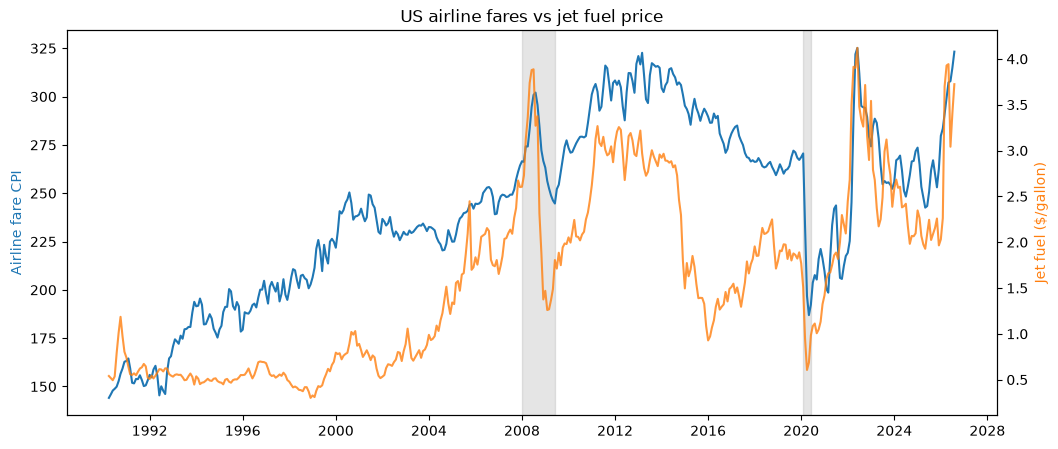

In [5]:
fig, ax1 = plt.subplots(figsize=(12, 5))
ax1.plot(data.index, data["airfare"], color="tab:blue")
ax1.set_ylabel("Airline fare CPI", color="tab:blue")

ax2 = ax1.twinx()
ax2.plot(data.index, data["jet_fuel"], color="tab:orange", alpha=0.8)
ax2.set_ylabel("Jet fuel ($/gallon)", color="tab:orange")

for start, end in [("2008-01", "2009-06"), ("2020-02", "2020-06")]:
    ax1.axvspan(pd.Timestamp(start), pd.Timestamp(end), color="grey", alpha=0.2)

plt.title("US airline fares vs jet fuel price")
plt.show()

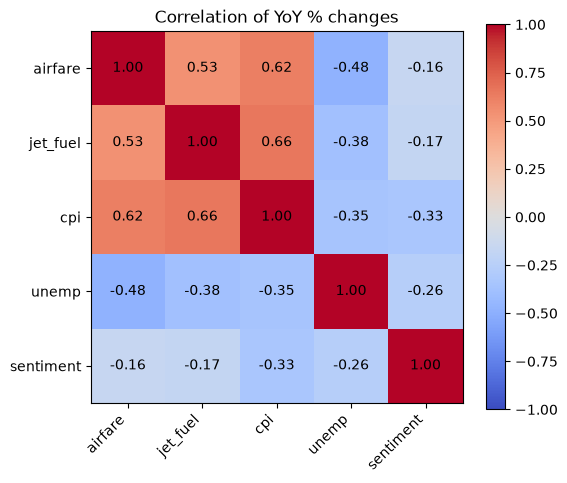

,airfare,jet_fuel,cpi,unemp,sentiment
airfare,1.00,0.53,0.62,-0.48,-0.16
jet_fuel,0.53,1.00,0.66,-0.38,-0.17
cpi,0.62,0.66,1.00,-0.35,-0.33
unemp,-0.48,-0.38,-0.35,1.00,-0.26
sentiment,-0.16,-0.17,-0.33,-0.26,1.00


In [6]:
yoy = data.pct_change(12).dropna() * 100
corr = yoy.corr()

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center")
fig.colorbar(im)
plt.title("Correlation of YoY % changes")
plt.show()

corr.round(2)

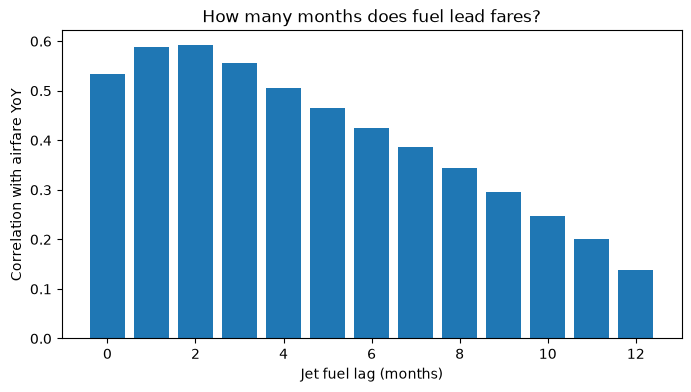

Best fuel lag: 2 months


In [7]:
lags = range(0, 13)
lag_corr = [yoy["airfare"].corr(yoy["jet_fuel"].shift(k)) for k in lags]

plt.figure(figsize=(8, 4))
plt.bar(lags, lag_corr)
plt.xlabel("Jet fuel lag (months)")
plt.ylabel("Correlation with airfare YoY")
plt.title("How many months does fuel lead fares?")
plt.show()

print("Best fuel lag:", max(lags, key=lambda k: lag_corr[k]), "months")